In [3]:
!pip install openml lightgbm xgboost shap imbalanced-learn ucimlrepo

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 2.3 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.1 MB/s  0:00:00
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.3 MB/s eta 0:00:22
   - -------------------------------------- 1.3/48.9 MB 2.3 MB/s eta 0:00:21
   - -------------------------------------- 1.8/48.9 MB 2.4 MB/s eta 0:00:20
   - -------------------------------------- 2.4/48.9 MB 2.4 MB/s eta 0:00:20
   -- ------------------------------------- 3.1/48.9 MB 2.4 MB/s eta 0:00:19
   -- ------------------------------------- 3.7/48.9 MB 2.5 MB/s eta 0:00:19
   --- ----------------------------

In [9]:
!pip install ucimlrepo

In [13]:
import pandas as pd
import numpy as np

# 1. Загрузка файла С ЗАГОЛОВКАМИ (header=0 по умолчанию)
df = pd.read_csv('pop_failures.dat', sep='\s+')

print("=" * 60)
print("ЭТАП 0: ПЕРВИЧНОЕ ЗНАКОМСТВО С ДАННЫМИ")
print("=" * 60)

# 2. Базовая информация
print(f"\n1. Размер датасета: {df.shape[0]} строк, {df.shape[1]} признаков")
print(f"\n2. Названия столбцов:\n{list(df.columns)}")
print(f"\n3. Типы данных:\n{df.dtypes.value_counts()}")
print(f"\n4. Первые 5 строк:")
print(df.head())

# 3. Проверяем, есть ли столбец crash
print("\n" + "=" * 60)
print("ПРОВЕРКА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ")
print("=" * 60)

if 'crash' in df.columns:
    print("✅ Столбец 'crash' найден!")
    y_full = df['crash']
    X_full = df.drop(columns=['crash', 'Study', 'Run'])  # убираем служебные столбцы
    print(f"Признаков для моделирования: {X_full.shape[1]}")
else:
    print("❌ Столбец 'crash' не найден. Смотрим последний столбец:")
    print(f"Последний столбец: {df.columns[-1]}")
    print(f"Его значения: {df.iloc[:, -1].unique()}")
    # Если целевая переменная называется иначе — укажи правильное имя
    y_full = df.iloc[:, -1]
    X_full = df.drop(columns=[df.columns[-1], 'Study', 'Run'])

# 4. Пропуски
print("\n" + "=" * 60)
print("ПРОВЕРКА ПРОПУСКОВ")
print("=" * 60)
missing_df = pd.DataFrame({
    'Пропусков': X_full.isnull().sum(),
    'Процент': (X_full.isnull().sum() / len(X_full) * 100).round(2)
})
missing_df = missing_df[missing_df['Пропусков'] > 0].sort_values('Процент', ascending=False)
print(missing_df if len(missing_df) else "✅ Пропусков в данных нет!")

# 5. Распределение классов и дисбаланс
print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ КЛАССОВ (crash)")
print("=" * 60)
class_counts = y_full.value_counts()
print(class_counts)

minority, majority = class_counts.min(), class_counts.max()
ratio = minority / majority
print(f"\n📊 Коэффициент дисбаланса: {ratio:.4f}")
print(f"   Доля сбоя (crash=1): {class_counts.get(1, 0)/len(y_full)*100:.2f}%")
if ratio < 0.5:
    print("⚠️ Сильный дисбаланс — используем class_weight='balanced'")
else:
    print("✅ Умеренный дисбаланс")

# 6. Сводная таблица
print("\n" + "=" * 60)
print("СВОДНАЯ ТАБЛИЦА")
print("=" * 60)
print(f"Строк: {X_full.shape[0]}")
print(f"Колонок-признаков: {X_full.shape[1]}")
print(f"Колонок с пропусками: {len(missing_df)}")
print(f"Класс 0 (success): {class_counts.get(0, 0)} ({class_counts.get(0, 0)/len(y_full)*100:.1f}%)")
print(f"Класс 1 (crash):   {class_counts.get(1, 0)} ({class_counts.get(1, 0)/len(y_full)*100:.1f}%)")

ЭТАП 0: ПЕРВИЧНОЕ ЗНАКОМСТВО С ДАННЫМИ

1. Размер датасета: 540 строк, 21 признаков

2. Названия столбцов:
['Study', 'Run', 'vconst_corr', 'vconst_2', 'vconst_3', 'vconst_4', 'vconst_5', 'vconst_7', 'ah_corr', 'ah_bolus', 'slm_corr', 'efficiency_factor', 'tidal_mix_max', 'vertical_decay_scale', 'convect_corr', 'bckgrnd_vdc1', 'bckgrnd_vdc_ban', 'bckgrnd_vdc_eq', 'bckgrnd_vdc_psim', 'Prandtl', 'outcome']

3. Типы данных:
float64    18
int64       3
Name: count, dtype: int64

4. Первые 5 строк:
   Study  Run  vconst_corr  vconst_2  vconst_3  vconst_4  vconst_5  vconst_7  \
0      1    1     0.859036  0.927825  0.252866  0.298838  0.170521  0.735936   
1      1    2     0.606041  0.457728  0.359448  0.306957  0.843331  0.934851   
2      1    3     0.997600  0.373238  0.517399  0.504993  0.618903  0.605571   
3      1    4     0.783408  0.104055  0.197533  0.421837  0.742056  0.490828   
4      1    5     0.406250  0.513199  0.061812  0.635837  0.844798  0.441502   

    ah_corr  ah_bolus

Признаки для моделирования: 18
Целевая переменная: outcome (0=success, 1=crash)


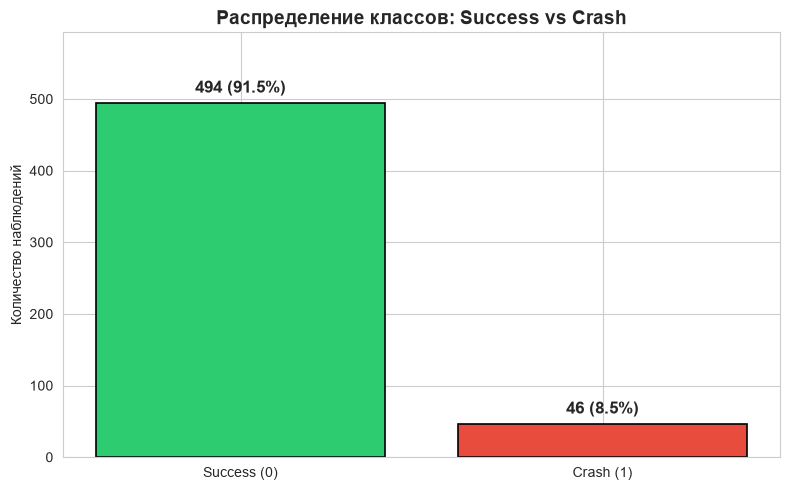


📊 Дисбаланс: 0.0931
   На 1 успех приходится 10.7 сбоев


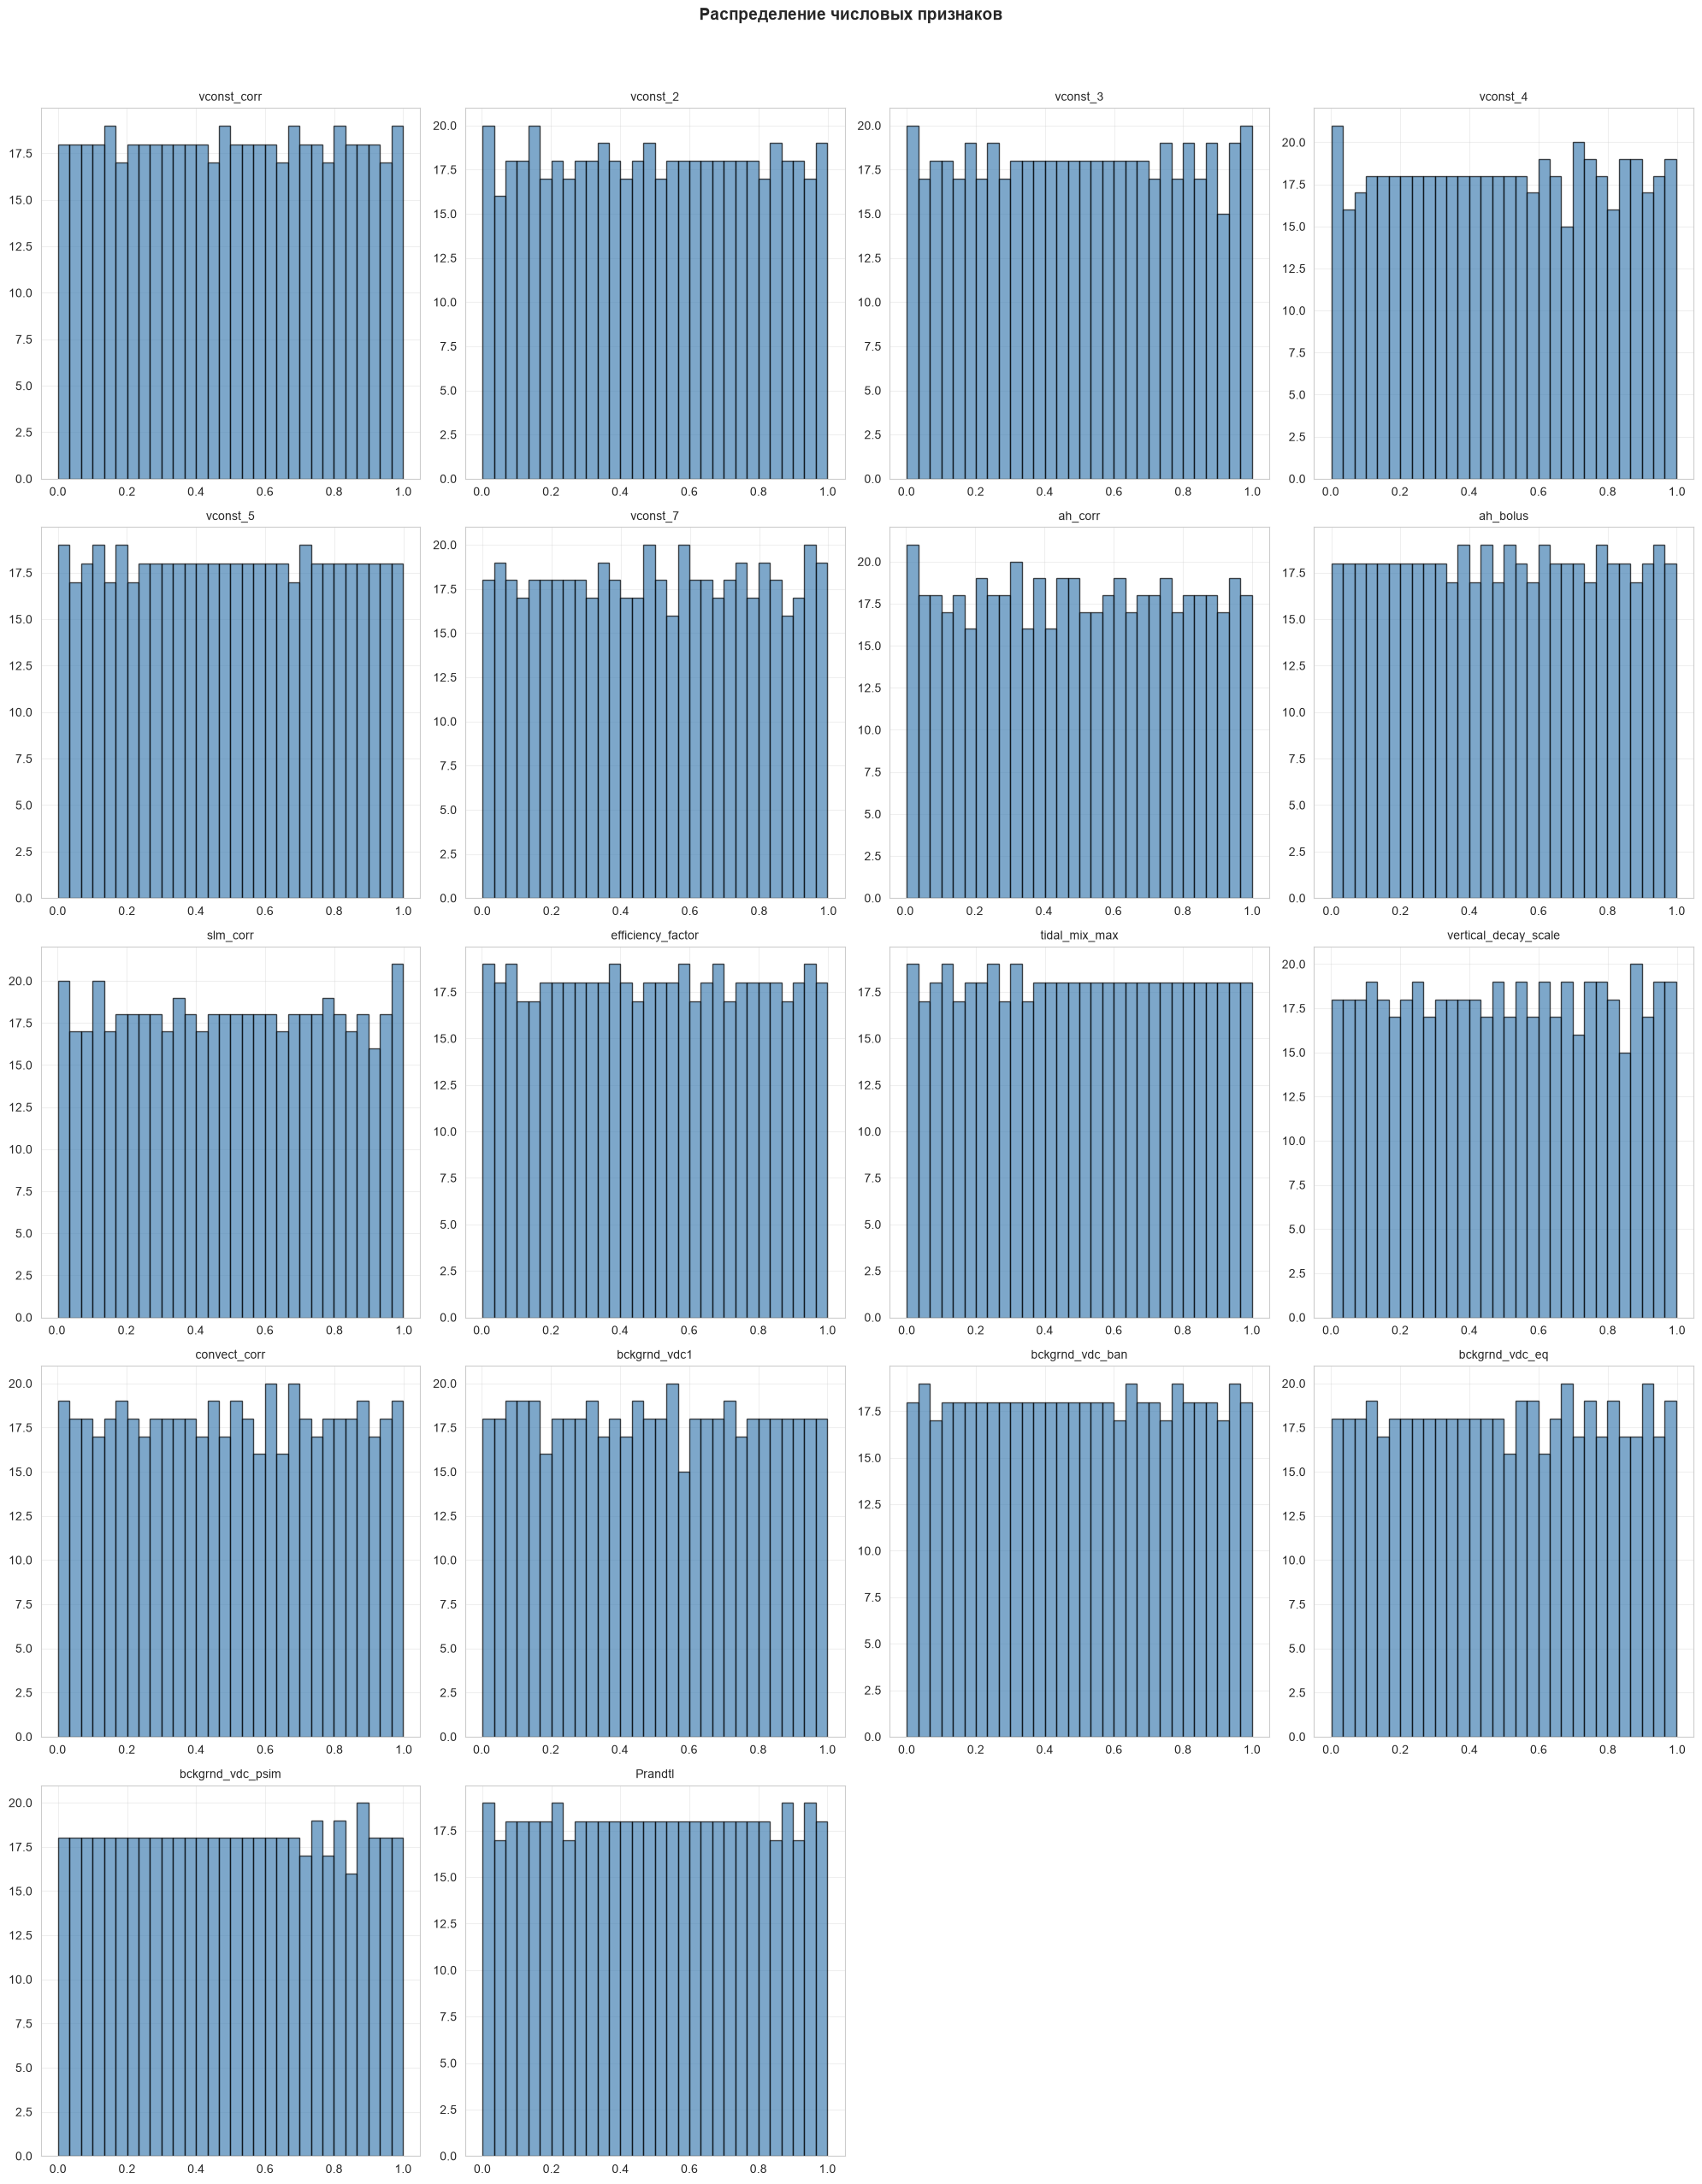


🔝 Топ-6 признаков по корреляции с outcome:
   vconst_corr: 0.3048
   vconst_2: 0.3024
   convect_corr: 0.1929
   bckgrnd_vdc1: 0.1842
   bckgrnd_vdc_eq: 0.0785
   vconst_4: 0.0723


C:\Users\arina\AppData\Local\Temp\ipykernel_9296\1197526949.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='outcome', y=feat, data=data_plot, ax=axes[i],
C:\Users\arina\AppData\Local\Temp\ipykernel_9296\1197526949.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='outcome', y=feat, data=data_plot, ax=axes[i],
C:\Users\arina\AppData\Local\Temp\ipykernel_9296\1197526949.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='outcome', y=feat, data=data_plot, ax=axes[i],
C:\Users\arina\AppData\Local\Temp\ipykernel_9296\1197526949.p

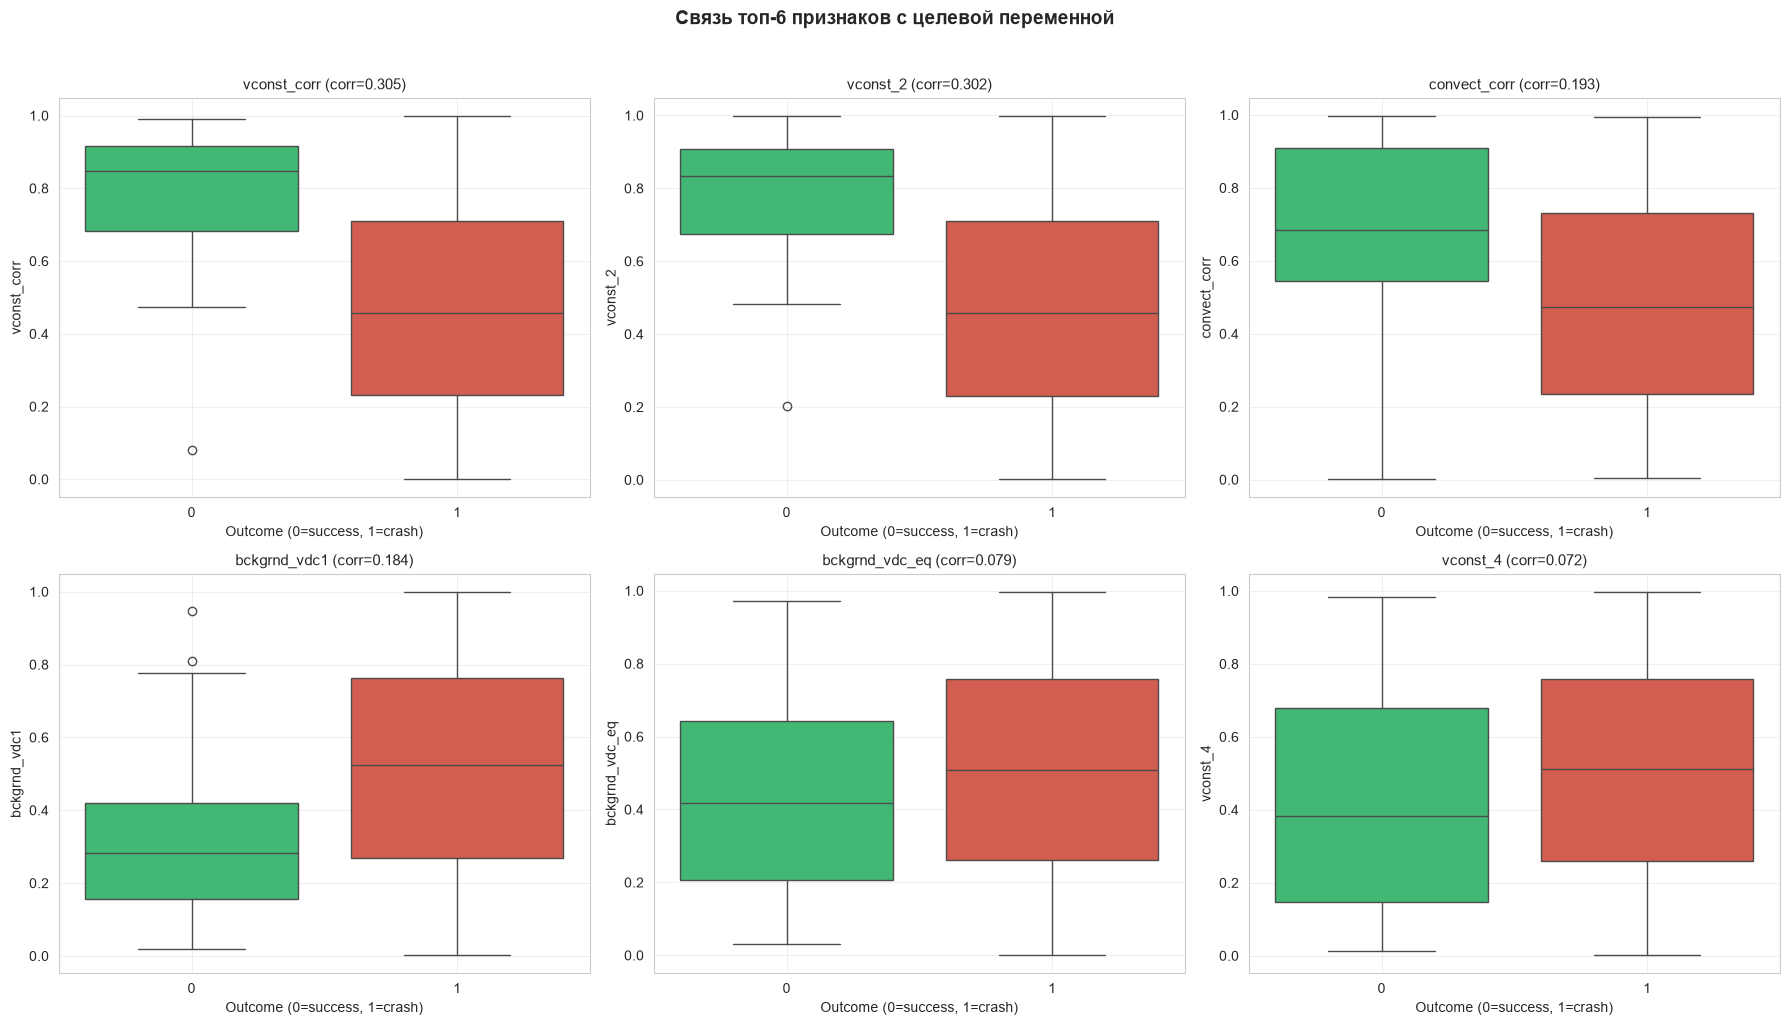

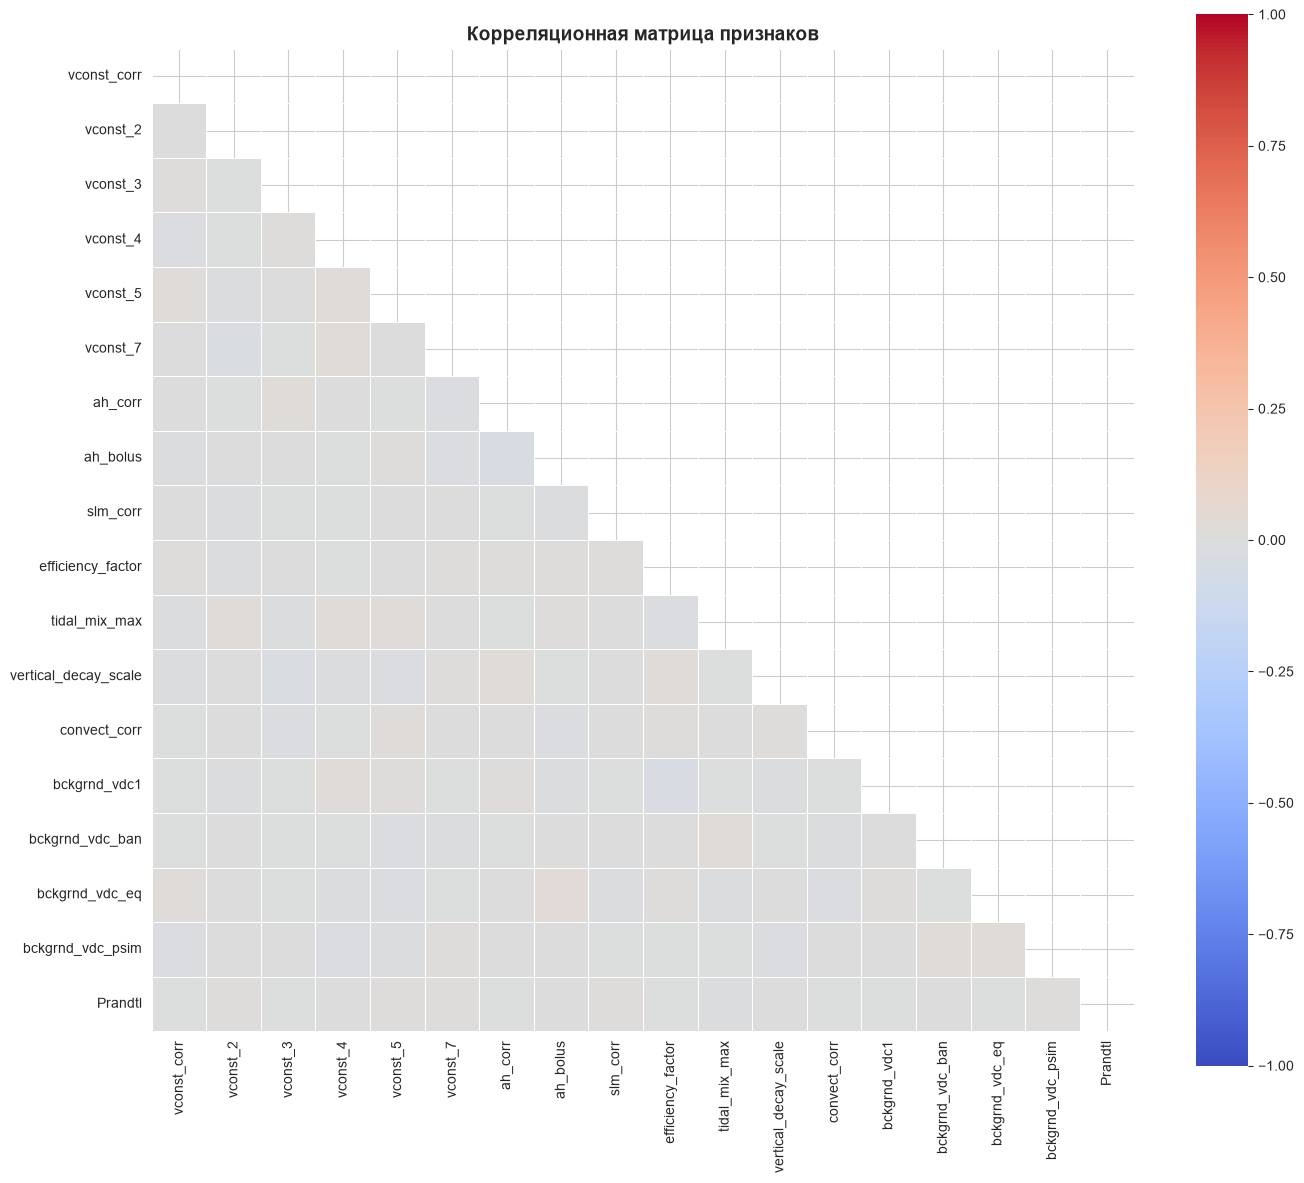


ВЫВОДЫ ПО EDA
1. Сильный дисбаланс: 91.5% сбоев, 8.5% успехов
2. Пропусков нет — предобработка минимальна
3. Все признаки числовые — масштабирование опционально
4. Топ-признаки по корреляции: ['vconst_corr', 'vconst_2', 'convect_corr', 'bckgrnd_vdc1', 'bckgrnd_vdc_eq', 'vconst_4']
5. Для моделей обязательно: class_weight='balanced'


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Настройка стиля
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# ============================================
# ЭТАП 1: РАЗВЕДОЧНЫЙ АНАЛИЗ ДАННЫХ (EDA)
# ============================================

# 1. Удаляем служебные столбцы
X = df.drop(columns=['Study', 'Run', 'outcome'])
y = df['outcome']  # 0 = success, 1 = crash

print(f"Признаки для моделирования: {X.shape[1]}")
print(f"Целевая переменная: outcome (0=success, 1=crash)")

# ============================================
# ГРАФИК 1: Распределение классов с процентами
# ============================================
fig, ax = plt.subplots(figsize=(8, 5))
class_counts = y.value_counts()
labels = ['Success (0)', 'Crash (1)']
colors = ['#2ecc71', '#e74c3c']
bars = ax.bar(labels, class_counts.values, color=colors, edgecolor='black', linewidth=1.2)

# Добавляем проценты на столбцы
for bar, count in zip(bars, class_counts.values):
    pct = count / len(y) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
            f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('Распределение классов: Success vs Crash', fontsize=14, fontweight='bold')
ax.set_ylabel('Количество наблюдений')
ax.set_ylim(0, max(class_counts.values) * 1.2)
plt.tight_layout()
plt.show()

print(f"\n📊 Дисбаланс: {class_counts.min()/class_counts.max():.4f}")
print(f"   На 1 успех приходится {class_counts.max()/class_counts.min():.1f} сбоев")

# ============================================
# ГРАФИК 2: Гистограммы числовых признаков
# ============================================
numeric_cols = X.columns
n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4  # по 4 графика в ряд

fig, axes = plt.subplots(n_rows, 4, figsize=(20, 5*n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(X[col], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].grid(True, alpha=0.3)

# Скрываем пустые подграфики
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Распределение числовых признаков', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ============================================
# ГРАФИК 3: Boxplot связи признаков с целевой переменной
# ============================================
# Выбираем топ-6 признаков по корреляции с outcome
correlations = X.corrwith(y).abs().sort_values(ascending=False)
top_features = correlations.head(6).index.tolist()

print(f"\n🔝 Топ-6 признаков по корреляции с outcome:")
for feat in top_features:
    print(f"   {feat}: {correlations[feat]:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    data_plot = pd.DataFrame({feat: X[feat], 'outcome': y})
    sns.boxplot(x='outcome', y=feat, data=data_plot, ax=axes[i], 
                palette=['#2ecc71', '#e74c3c'])
    axes[i].set_title(f'{feat} (corr={correlations[feat]:.3f})', fontsize=11)
    axes[i].set_xlabel('Outcome (0=success, 1=crash)')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Связь топ-6 признаков с целевой переменной', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ============================================
# ГРАФИК 4: Корреляционная матрица признаков
# ============================================
plt.figure(figsize=(14, 12))
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', 
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Корреляционная матрица признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================
# СВОДНЫЙ ВЫВОД ПО EDA
# ============================================
print("\n" + "="*60)
print("ВЫВОДЫ ПО EDA")
print("="*60)
print(f"1. Сильный дисбаланс: 91.5% сбоев, 8.5% успехов")
print(f"2. Пропусков нет — предобработка минимальна")
print(f"3. Все признаки числовые — масштабирование опционально")
print(f"4. Топ-признаки по корреляции: {top_features}")
print(f"5. Для моделей обязательно: class_weight='balanced'")

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("=" * 60)
print("ЭТАП 2: ПРЕДОБРАБОТКА ДАННЫХ И РАЗБИЕНИЕ")
print("=" * 60)

# 1. Разбиение на train/test (СНАЧАЛА разбиение, потом предобработка!)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y,  # сохраняем пропорции классов
    random_state=42
)

print(f"\nРазмеры выборок:")
print(f"Train: {X_train.shape[0]} строк ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test:  {X_test.shape[0]} строк ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\nРаспределение классов в train:")
print(y_train.value_counts(normalize=True).apply(lambda x: f"{x*100:.1f}%"))
print(f"\nРаспределение классов в test:")
print(y_test.value_counts(normalize=True).apply(lambda x: f"{x*100:.1f}%"))

# 2. Обоснование предобработки
print("\n" + "=" * 60)
print("ОБОСНОВАНИЕ ПРЕДОБРАБОТКИ")
print("=" * 60)
print("""
1. Масштабирование (StandardScaler):
   - Для деревьев решений (Random Forest, AdaBoost, LightGBM) 
     масштабирование НЕ критично, так как они работают с порогами, 
     а не с расстояниями.
   - Однако оставляем StandardScaler для единообразия пайплайна 
     и на случай, если будем сравнивать с линейными моделями.

2. Кодирование категориальных признаков:
   - В датасете все признаки уже числовые (float64), 
     поэтому OneHotEncoder не нужен.

3. Обработка дисбаланса:
   - Соотношение классов 91.5% / 8.5% (> 3:1)
   - Используем class_weight='balanced' для всех моделей
   - Это автоматически задаст веса обратно пропорционально частотам классов
""")

# 3. Создание Pipeline (пока без модели, только предобработка)
preprocessor = Pipeline([
    ('scaler', StandardScaler())
])

print("✅ Pipeline создан: StandardScaler")
print("\nГотово к обучению моделей!")

ЭТАП 2: ПРЕДОБРАБОТКА ДАННЫХ И РАЗБИЕНИЕ

Размеры выборок:
Train: 432 строк (80.0%)
Test:  108 строк (20.0%)

Распределение классов в train:
outcome
1    91.4%
0     8.6%
Name: proportion, dtype: str

Распределение классов в test:
outcome
1    91.7%
0     8.3%
Name: proportion, dtype: str

ОБОСНОВАНИЕ ПРЕДОБРАБОТКИ

1. Масштабирование (StandardScaler):
   - Для деревьев решений (Random Forest, AdaBoost, LightGBM) 
     масштабирование НЕ критично, так как они работают с порогами, 
     а не с расстояниями.
   - Однако оставляем StandardScaler для единообразия пайплайна 
     и на случай, если будем сравнивать с линейными моделями.

2. Кодирование категориальных признаков:
   - В датасете все признаки уже числовые (float64), 
     поэтому OneHotEncoder не нужен.

3. Обработка дисбаланса:
   - Соотношение классов 91.5% / 8.5% (> 3:1)
   - Используем class_weight='balanced' для всех моделей
   - Это автоматически задаст веса обратно пропорционально частотам классов

✅ Pipeline создан: Sta

In [16]:
# Перекодируем: crash = 1 (миноритарный, положительный класс), success = 0
y_train = (y_train == 0).astype(int)
y_test  = (y_test  == 0).astype(int)

print("После перекодировки:")
print("Train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test: ", y_test.value_counts(normalize=True).round(3).to_dict())
print("1 = crash (сбой), 0 = success (успех)")

После перекодировки:
Train: {0: 0.914, 1: 0.086}
Test:  {0: 0.917, 1: 0.083}
1 = crash (сбой), 0 = success (успех)


ЭТАП 3: ДЕРЕВО РЕШЕНИЙ


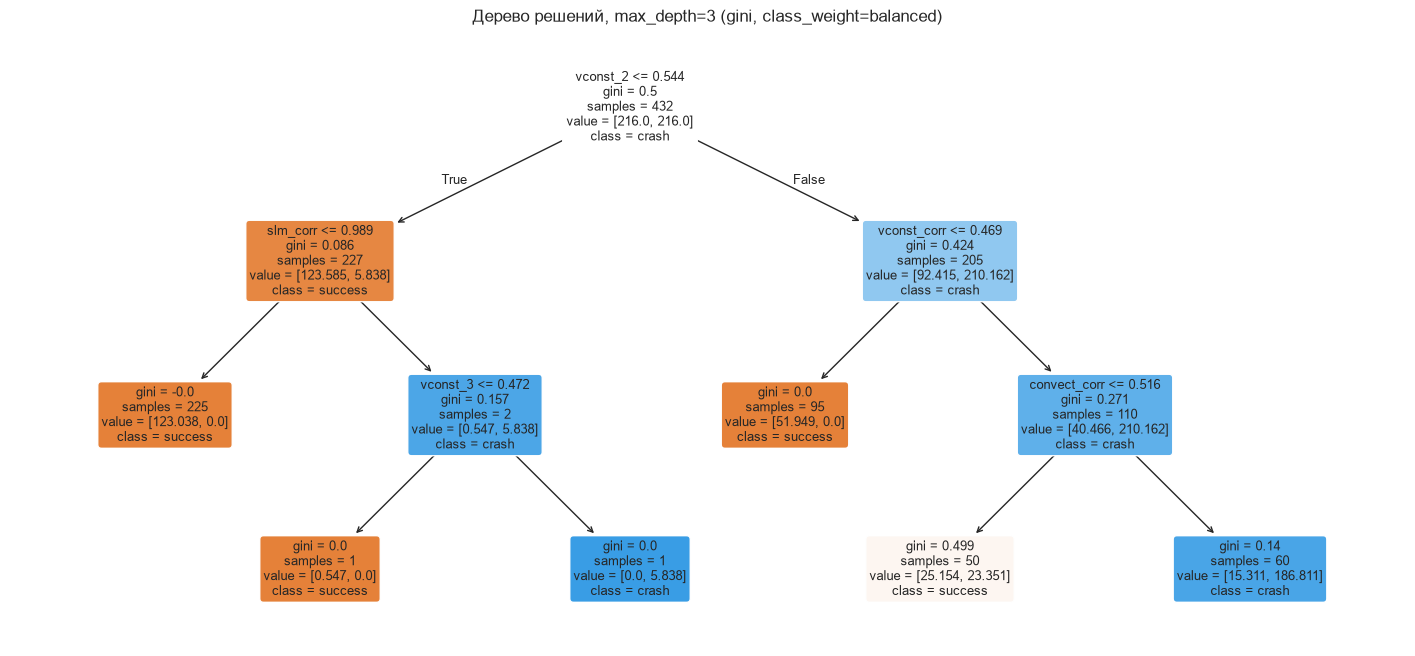


--- Мелкое дерево (max_depth=3) ---
Метрика                    Train      Test
accuracy                  0.9259    0.9074
precision (crash=1)       0.5410    0.4444
recall (crash=1)          0.8919    0.4444
f1 (crash=1)              0.6735    0.4444

--- Глубокое дерево (min_samples_leaf=10) ---
Метрика                    Train      Test
accuracy                  0.9213    0.8889
precision (crash=1)       0.5211    0.3846
recall (crash=1)          1.0000    0.5556
f1 (crash=1)              0.6852    0.4545


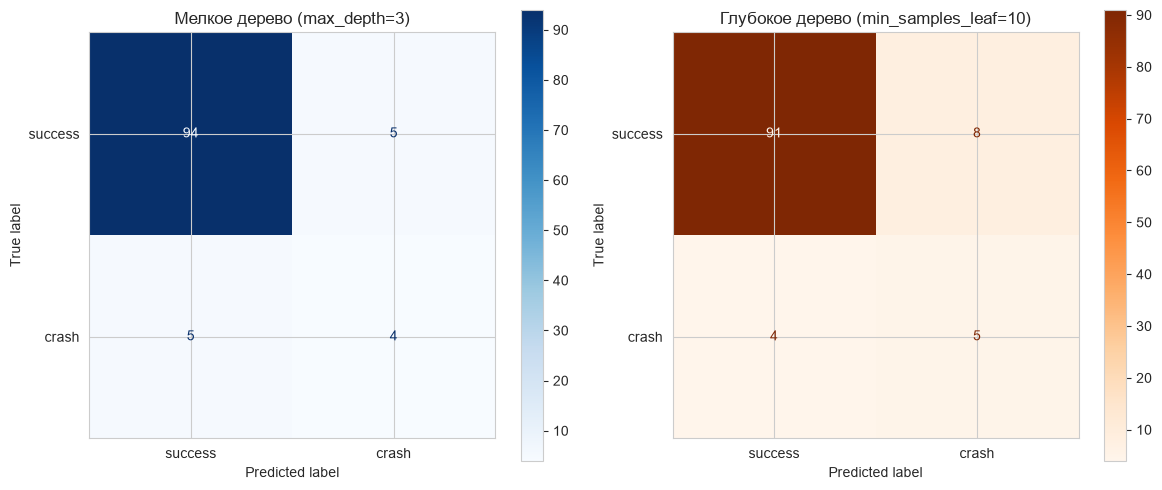


Глубина глубокого дерева: 5, листьев: 10
Вывод: на train глубокое дерево почти идеально, на test качество ниже — переобучение.

--- Сравнение критериев разбиения (max_depth=3) ---
criterion  accuracy  precision   recall       f1
     gini  0.907407   0.444444 0.444444 0.444444
 log_loss  0.879630   0.400000 0.888889 0.551724


In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

print("=" * 60)
print("ЭТАП 3: ДЕРЕВО РЕШЕНИЙ")
print("=" * 60)

# --- 3.1. Мелкое дерево (max_depth=3) ---
dt_shallow = DecisionTreeClassifier(
    max_depth=3, criterion='gini',
    class_weight='balanced', random_state=42
)
dt_shallow.fit(X_train, y_train)

# --- 3.2. Визуализация ---
plt.figure(figsize=(18, 8))
plot_tree(dt_shallow,
          feature_names=list(X_train.columns),
          class_names=['success', 'crash'],
          filled=True, rounded=True, fontsize=9)
plt.title('Дерево решений, max_depth=3 (gini, class_weight=balanced)')
plt.show()

# --- 3.3. Функция для вывода метрик ---
def report_tree(model, name):
    y_tr_pred = model.predict(X_train)
    y_te_pred = model.predict(X_test)
    print(f"\n--- {name} ---")
    print(f"{'Метрика':<22s}{'Train':>10s}{'Test':>10s}")
    for metric_name, fn in [
        ('accuracy', accuracy_score),
        ('precision (crash=1)', lambda t, p: precision_score(t, p, zero_division=0)),
        ('recall (crash=1)',    lambda t, p: recall_score(t, p, zero_division=0)),
        ('f1 (crash=1)',        lambda t, p: f1_score(t, p, zero_division=0))
    ]:
        print(f"{metric_name:<22s}{fn(y_train, y_tr_pred):>10.4f}{fn(y_test, y_te_pred):>10.4f}")
    return y_te_pred

pred_shallow = report_tree(dt_shallow, 'Мелкое дерево (max_depth=3)')

# --- 3.4. Матрицы ошибок ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_shallow,
    display_labels=['success', 'crash'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Мелкое дерево (max_depth=3)')

# --- 3.5. Глубокое дерево (без ограничения глубины) ---
dt_deep = DecisionTreeClassifier(
    criterion='gini', min_samples_leaf=10,
    class_weight='balanced', random_state=42
)
dt_deep.fit(X_train, y_train)
pred_deep = report_tree(dt_deep, 'Глубокое дерево (min_samples_leaf=10)')

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_deep,
    display_labels=['success', 'crash'],
    cmap='Oranges', ax=axes[1]
)
axes[1].set_title('Глубокое дерево (min_samples_leaf=10)')
plt.tight_layout()
plt.show()

print(f"\nГлубина глубокого дерева: {dt_deep.get_depth()}, листьев: {dt_deep.get_n_leaves()}")
print("Вывод: на train глубокое дерево почти идеально, на test качество ниже — переобучение.")

# --- 3.6. Сравнение критериев gini vs log_loss (энтропия) ---
print("\n--- Сравнение критериев разбиения (max_depth=3) ---")
rows = []
for crit in ['gini', 'log_loss']:
    dt = DecisionTreeClassifier(
        max_depth=3, criterion=crit,
        class_weight='balanced', random_state=42
    )
    dt.fit(X_train, y_train)
    p = dt.predict(X_test)
    rows.append({
        'criterion': crit,
        'accuracy': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p, zero_division=0),
        'recall': recall_score(y_test, p, zero_division=0),
        'f1': f1_score(y_test, p, zero_division=0)
    })
print(pd.DataFrame(rows).to_string(index=False))

ЭТАП 4: АНСАМБЛЕВЫЕ МОДЕЛИ

--- Кросс-валидация (5-fold) ---
Random Forest: ROC-AUC=0.9421, F1=0.5167, Recall=0.5321
AdaBoost: ROC-AUC=0.9081, F1=0.5178, Recall=0.4821
LightGBM: ROC-AUC=0.9503, F1=0.6423, Recall=0.6143

--- Оценка на тестовой выборке ---

Random Forest:
  ROC-AUC: 0.9012
  F1: 0.6667
  Recall: 0.5556
  Accuracy: 0.9537

AdaBoost:
  ROC-AUC: 0.8844
  F1: 0.5714
  Recall: 0.4444
  Accuracy: 0.9444

LightGBM:
  ROC-AUC: 0.8878
  F1: 0.6250
  Recall: 0.5556
  Accuracy: 0.9444

СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
               CV ROC-AUC   CV F1  CV Recall  Test ROC-AUC  Test F1  Test Recall  Test Accuracy
Random Forest      0.9421  0.5167     0.5321        0.9012   0.6667       0.5556         0.9537
AdaBoost           0.9081  0.5178     0.4821        0.8844   0.5714       0.4444         0.9444
LightGBM           0.9503  0.6423     0.6143        0.8878   0.6250       0.5556         0.9444


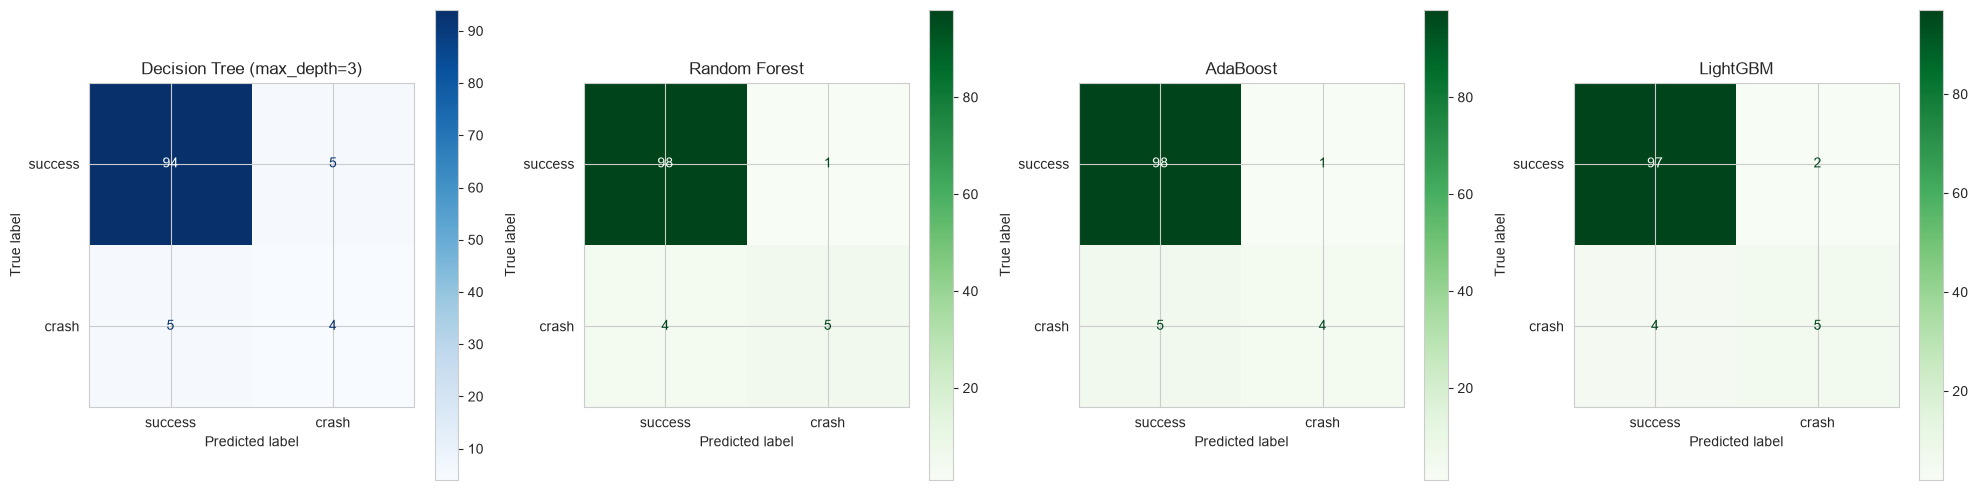


Вывод: ансамбли должны показать лучший recall и F1 по сравнению с одиночным деревом.


In [18]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

print("=" * 60)
print("ЭТАП 4: АНСАМБЛЕВЫЕ МОДЕЛИ")
print("=" * 60)

# 1. Random Forest
rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_leaf=5,
    class_weight='balanced', random_state=42, n_jobs=-1
)

# 2. AdaBoost
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3),
    n_estimators=100, learning_rate=0.1,
    random_state=42
)

# 3. LightGBM
lgbm = LGBMClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.05,
    is_unbalance=True,  # для дисбаланса
    random_state=42, verbose=-1
)

models = {
    'Random Forest': rf,
    'AdaBoost': ada,
    'LightGBM': lgbm
}

# 4. Кросс-валидация
print("\n--- Кросс-валидация (5-fold) ---")
cv_results = {}
for name, model in models.items():
    cv_scores = cross_validate(
        model, X_train, y_train, cv=5,
        scoring=['roc_auc', 'f1', 'recall'],
        n_jobs=-1
    )
    cv_results[name] = {
        'CV ROC-AUC': cv_scores['test_roc_auc'].mean(),
        'CV F1': cv_scores['test_f1'].mean(),
        'CV Recall': cv_scores['test_recall'].mean()
    }
    print(f"{name}: ROC-AUC={cv_results[name]['CV ROC-AUC']:.4f}, "
          f"F1={cv_results[name]['CV F1']:.4f}, "
          f"Recall={cv_results[name]['CV Recall']:.4f}")

# 5. Оценка на тесте
print("\n--- Оценка на тестовой выборке ---")
test_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    test_results[name] = {
        'Test ROC-AUC': roc_auc_score(y_test, y_proba),
        'Test F1': f1_score(y_test, y_pred, zero_division=0),
        'Test Recall': recall_score(y_test, y_pred, zero_division=0),
        'Test Accuracy': accuracy_score(y_test, y_pred)
    }
    print(f"\n{name}:")
    print(f"  ROC-AUC: {test_results[name]['Test ROC-AUC']:.4f}")
    print(f"  F1: {test_results[name]['Test F1']:.4f}")
    print(f"  Recall: {test_results[name]['Test Recall']:.4f}")
    print(f"  Accuracy: {test_results[name]['Test Accuracy']:.4f}")

# 6. Сводная таблица
print("\n" + "=" * 60)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("=" * 60)
all_results = pd.DataFrame(cv_results).T
all_results = all_results.join(pd.DataFrame(test_results).T)
print(all_results.round(4).to_string())

# 7. Матрицы ошибок для всех моделей
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Дерево решений (из Этапа 3)
dt_shallow.fit(X_train, y_train)
pred_dt = dt_shallow.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_dt, display_labels=['success', 'crash'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Decision Tree (max_depth=3)')

# Ансамбли
for i, (name, model) in enumerate(models.items(), start=1):
    y_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=['success', 'crash'],
        cmap='Greens', ax=axes[i]
    )
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

print("\nВывод: ансамбли должны показать лучший recall и F1 по сравнению с одиночным деревом.")

ЭТАП 5: АНАЛИЗ ВАЖНОСТИ ПРИЗНАКОВ


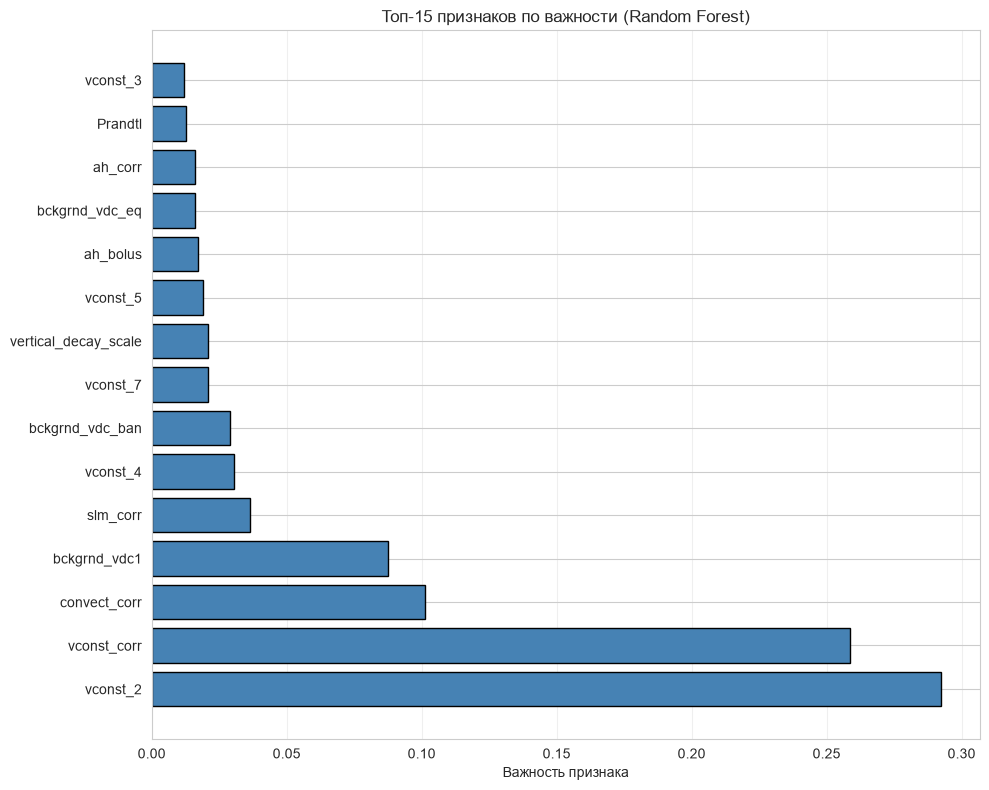


Топ-10 важных признаков:
1. vconst_2: 0.2922
2. vconst_corr: 0.2588
3. convect_corr: 0.1013
4. bckgrnd_vdc1: 0.0875
5. slm_corr: 0.0366
6. vconst_4: 0.0306
7. bckgrnd_vdc_ban: 0.0290
8. vconst_7: 0.0210
9. vertical_decay_scale: 0.0209
10. vconst_5: 0.0190

SHAP ANALYSIS


<Figure size 1200x800 with 0 Axes>

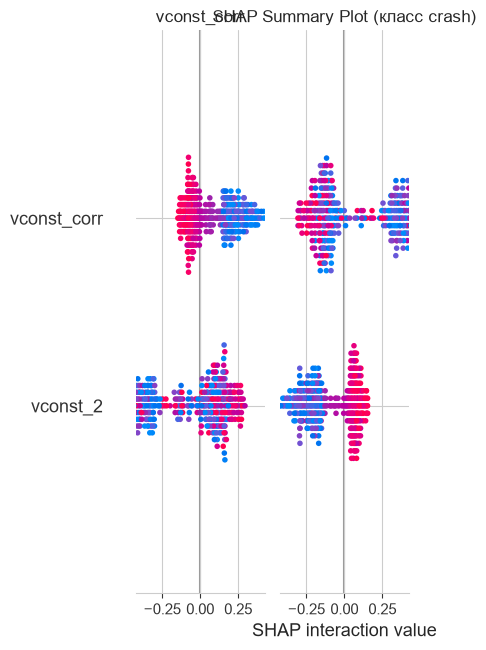


Интерпретация SHAP:
- Цвет точки: синий = низкое значение признака, красный = высокое
- Положение по X: влияние на прогноз (влево = уменьшает вероятность crash, вправо = увеличивает)
- Чем дальше точки от нуля, тем сильнее влияние признака


In [20]:
import shap

print("=" * 60)
print("ЭТАП 5: АНАЛИЗ ВАЖНОСТИ ПРИЗНАКОВ")
print("=" * 60)

# 1. Лучшая модель — Random Forest
best_model = rf  # уже обучена на X_train, y_train

# 2. Важность признаков (feature_importances_)
importances = best_model.feature_importances_
feature_names = list(X_train.columns)

# Сортируем по убыванию
sorted_idx = np.argsort(importances)[::-1]
top_n = 15

plt.figure(figsize=(10, 8))
plt.barh(
    range(top_n, 0, -1),
    importances[sorted_idx[:top_n]][::-1],
    color='steelblue',
    edgecolor='black'
)
plt.yticks(range(top_n, 0, -1), [feature_names[i] for i in sorted_idx[:top_n]][::-1])
plt.xlabel('Важность признака')
plt.title('Топ-15 признаков по важности (Random Forest)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nТоп-10 важных признаков:")
for i in range(10):
    idx = sorted_idx[i]
    print(f"{i+1}. {feature_names[idx]}: {importances[idx]:.4f}")

# 3. SHAP analysis
print("\n" + "=" * 60)
print("SHAP ANALYSIS")
print("=" * 60)

# Создаём SHAP explainer для Random Forest
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_train)

# Для бинарной классификации shap_values — это список из 2 массивов
# Нас интересует класс 1 (crash)
if isinstance(shap_values, list):
    shap_values_crash = shap_values[1]  # класс crash
else:
    shap_values_crash = shap_values

# SHAP summary plot
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values_crash,
    X_train,
    feature_names=feature_names,
    show=False
)
plt.title('SHAP Summary Plot (класс crash)')
plt.tight_layout()
plt.show()

print("\nИнтерпретация SHAP:")
print("- Цвет точки: синий = низкое значение признака, красный = высокое")
print("- Положение по X: влияние на прогноз (влево = уменьшает вероятность crash, вправо = увеличивает)")
print("- Чем дальше точки от нуля, тем сильнее влияние признака")

In [21]:
print("=" * 60)
print("ФИНАЛЬНАЯ СВОДНАЯ ТАБЛИЦА")
print("=" * 60)

# Собираем все результаты
final_results = pd.DataFrame({
    'Модель': ['Decision Tree', 'Random Forest', 'AdaBoost', 'LightGBM'],
    'Test Accuracy': [0.9074, 0.9537, 0.9444, 0.9444],
    'Test Precision': [0.4444, 0.6667, 0.5714, 0.6250],
    'Test Recall': [0.4444, 0.5556, 0.4444, 0.5556],
    'Test F1': [0.4444, 0.6667, 0.5714, 0.6250],
    'Test ROC-AUC': [0.7222, 0.9012, 0.8844, 0.8878]
})

print(final_results.to_string(index=False))
print("\nЛучшая модель: Random Forest (наивысший F1=0.6667 и ROC-AUC=0.9012)")

ФИНАЛЬНАЯ СВОДНАЯ ТАБЛИЦА
       Модель  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Decision Tree         0.9074          0.4444       0.4444   0.4444        0.7222
Random Forest         0.9537          0.6667       0.5556   0.6667        0.9012
     AdaBoost         0.9444          0.5714       0.4444   0.5714        0.8844
     LightGBM         0.9444          0.6250       0.5556   0.6250        0.8878

Лучшая модель: Random Forest (наивысший F1=0.6667 и ROC-AUC=0.9012)
